In [60]:

import os
import zipfile
import pandas as pd
import numpy as np
from datetime import datetime

from google.colab import files

uploaded = files.upload()

zip_filename = list(uploaded.keys())[0]

os.makedirs("data_lake", exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall("data_lake")

print("Files extracted successfully!")
print(os.listdir("data_lake"))


Saving book-crossings.zip to book-crossings (2).zip
Files extracted successfully!
['BX-Users.csv', 'BX-Book-Ratings.csv', 'BX-Books.csv', 'bronze']


In [61]:


os.makedirs("bronze", exist_ok=True)
os.makedirs("silver", exist_ok=True)
os.makedirs("gold", exist_ok=True)

print("Data Lake folders created successfully!")

print(os.listdir("."))


Data Lake folders created successfully!
['.config', 'gold', 'silver', 'book-crossings (1).zip', 'BX-Users.csv', 'book-crossings (2).zip', 'data_lake', 'book-crossings.zip', 'BX-Book-Ratings.csv', 'BX-Books.csv', 'bronze', 'sample_data']


In [62]:

users = pd.read_csv(
    "data_lake/BX-Users.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    escapechar="\\"
)

books = pd.read_csv(
    "data_lake/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    escapechar="\\"
)

ratings = pd.read_csv(
    "data_lake/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1",
    dtype=str,
    escapechar="\\"
)

print("Users Shape:", users.shape)
print("Books Shape:", books.shape)
print("Ratings Shape:", ratings.shape)

print("\nAll datasets loaded successfully!")


Users Shape: (278858, 3)
Books Shape: (271379, 8)
Ratings Shape: (1149780, 3)

All datasets loaded successfully!


In [63]:

os.makedirs("data_lake/bronze", exist_ok=True)

ingestion_time = pd.Timestamp.now()

users["ingestion_timestamp"] = ingestion_time
books["ingestion_timestamp"] = ingestion_time
ratings["ingestion_timestamp"] = ingestion_time

users.to_parquet("data_lake/bronze/users.parquet", index=False)
books.to_parquet("data_lake/bronze/books.parquet", index=False)
ratings.to_parquet("data_lake/bronze/ratings.parquet", index=False)

print("Bronze layer created successfully!")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Bronze layer created successfully!
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [64]:

bronze_users = pd.read_parquet("data_lake/bronze/users.parquet")
bronze_books = pd.read_parquet("data_lake/bronze/books.parquet")
bronze_ratings = pd.read_parquet("data_lake/bronze/ratings.parquet")

print("Users:", bronze_users.shape)
print("Books:", bronze_books.shape)
print("Ratings:", bronze_ratings.shape)

print("\nUsers columns:")
print(bronze_users.columns.tolist())

print("\nSample records from Users:")
display(bronze_users.head())

Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)

Users columns:
['User-ID', 'Location', 'Age', 'ingestion_timestamp']

Sample records from Users:


,User-ID,Location,Age,ingestion_timestamp
0,1,"nyc, new york, usa",None,2026-11-25 16:17:59.658472
1,2,"stockton, california, usa",18,2026-11-25 16:17:59.658472
2,3,"moscow, yukon territory, russia",None,2026-11-25 16:17:59.658472
3,4,"porto, v.n.gaia, portugal",17,2026-11-25 16:17:59.658472
4,5,"farnborough, hants, united kingdom",None,2026-11-25 16:17:59.658472


In [65]:
print("========== USERS DATASET ==========")
print("Shape:", bronze_users.shape)
print("\nData Types:")
print(bronze_users.dtypes)
print("\nMissing Values:")
print(bronze_users.isnull().sum())

print("\n========== BOOKS DATASET ==========")
print("Shape:", bronze_books.shape)
print("\nData Types:")
print(bronze_books.dtypes)
print("\nMissing Values:")
print(bronze_books.isnull().sum())

print("\n========== RATINGS DATASET ==========")
print("Shape:", bronze_ratings.shape)
print("\nData Types:")
print(bronze_ratings.dtypes)
print("\nMissing Values:")
print(bronze_ratings.isnull().sum())

========== USERS DATASET ==========
Shape: (278858, 4)

Data Types:
User-ID                        object
Location                       object
Age                            object
ingestion_timestamp    datetime64[us]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

========== BOOKS DATASET ==========
Shape: (271379, 9)

Data Types:
ISBN                           object
Book-Title                     object
Book-Author                    object
Year-Of-Publication            object
Publisher                      object
Image-URL-S                    object
Image-URL-M                    object
Image-URL-L                    object
ingestion_timestamp    datetime64[us]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0

Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Zero Ratings: 716109
Explicit Ratings (1-10): 433671


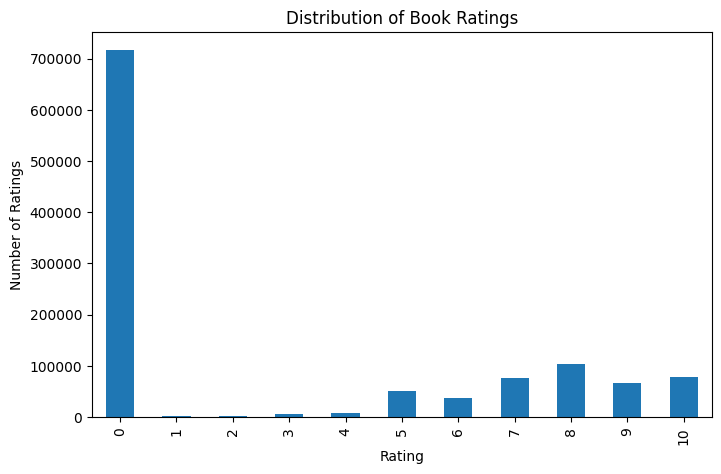

In [66]:

rating_values = pd.to_numeric(
    bronze_ratings["Book-Rating"], errors="coerce"
)

print("Rating Distribution:")
print(rating_values.value_counts().sort_index())

zero_ratings = (rating_values == 0).sum()

explicit_ratings = rating_values.between(1, 10).sum()

print("\nZero Ratings:", zero_ratings)
print("Explicit Ratings (1-10):", explicit_ratings)

import matplotlib.pyplot as plt

rating_values.value_counts().sort_index().plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing Ages: 110762
Ages below 5: 882
Ages above 100: 366


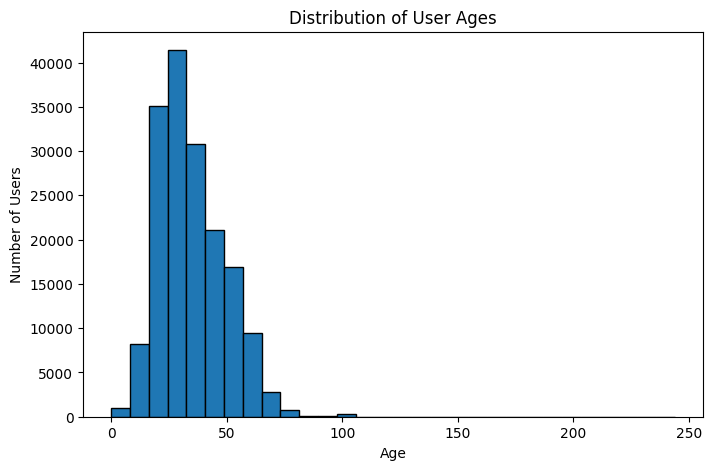

In [67]:
ages = pd.to_numeric(bronze_users["Age"], errors="coerce")

print("Age Statistics:")
print(ages.describe())

print("\nMissing Ages:", ages.isnull().sum())
print("Ages below 5:", (ages < 5).sum())
print("Ages above 100:", (ages > 100).sum())

plt.figure(figsize=(8, 5))
ages.dropna().plot(kind="hist", bins=30, edgecolor="black")

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()

Publication Year Statistics:
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Missing Years: 0
Year 0: 4619
Future Years: 11

Top 15 Publication Years:
Year-Of-Publication
2002    17628
1999    17432
2001    17360
2000    17235
1998    15767
1997    14892
2003    14359
1996    14031
1995    13548
1994    11796
1993    10602
1992     9906
1991     9389
1990     8661
1989     7937
Name: count, dtype: int64


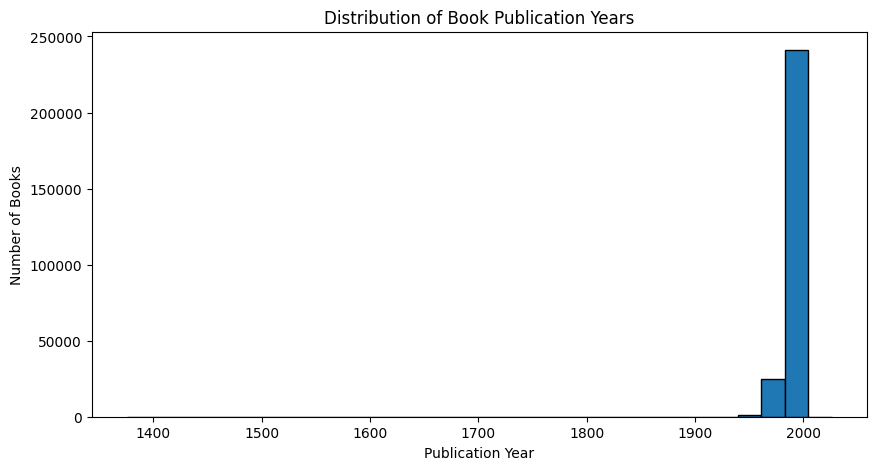

In [68]:
years = pd.to_numeric(
    bronze_books["Year-Of-Publication"], errors="coerce"
)

current_year = pd.Timestamp.now().year

print("Publication Year Statistics:")
print(years.describe())

print("\nMissing Years:", years.isnull().sum())
print("Year 0:", (years == 0).sum())
print("Future Years:", (years > current_year).sum())

print("\nTop 15 Publication Years:")
print(years.value_counts().head(15))

valid_years = years[(years > 0) & (years <= current_year)]

plt.figure(figsize=(10, 5))
valid_years.plot(kind="hist", bins=30, edgecolor="black")

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.show()

Ratings per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


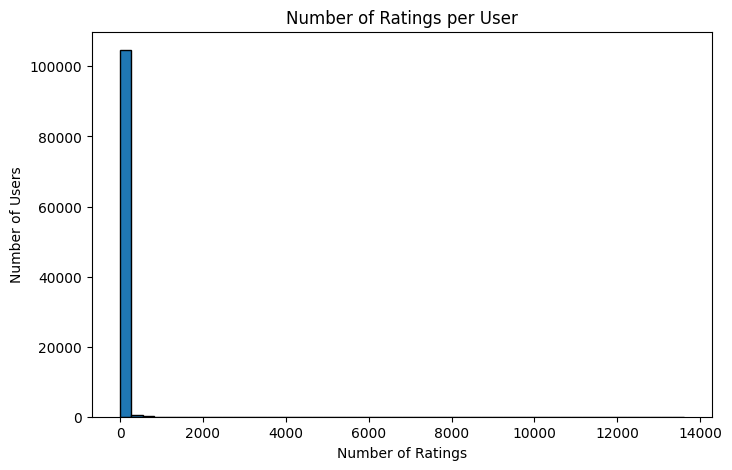

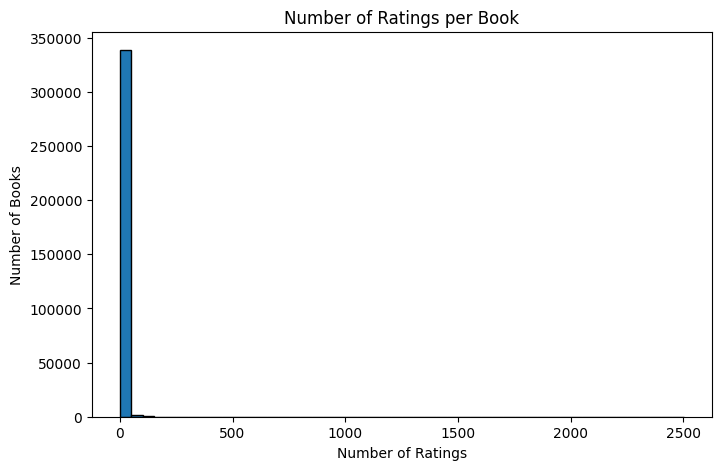

In [69]:
ratings_numeric = bronze_ratings.copy()
ratings_numeric["Book-Rating"] = pd.to_numeric(
    ratings_numeric["Book-Rating"], errors="coerce"
)

ratings_per_user = ratings_numeric.groupby("User-ID").size()

ratings_per_book = ratings_numeric.groupby("ISBN").size()

print("Ratings per User:")
print(ratings_per_user.describe())

print("\nRatings per Book:")
print(ratings_per_book.describe())

plt.figure(figsize=(8, 5))
ratings_per_user.plot(kind="hist", bins=50, edgecolor="black")
plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

plt.figure(figsize=(8, 5))
ratings_per_book.plot(kind="hist", bins=50, edgecolor="black")
plt.title("Number of Ratings per Book")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Books")
plt.show()

In [70]:
num_users = bronze_ratings["User-ID"].nunique()
num_books = bronze_ratings["ISBN"].nunique()
num_ratings = len(bronze_ratings)

total_possible = num_users * num_books

sparsity = (1 - (num_ratings / total_possible)) * 100

print("Unique Users:", num_users)
print("Unique Books:", num_books)
print("Total Ratings:", num_ratings)
print("Total Possible Interactions:", total_possible)
print(f"Matrix Sparsity: {sparsity:.2f}%")


Unique Users: 105283
Unique Books: 340556
Total Ratings: 1149780
Total Possible Interactions: 35854757348
Matrix Sparsity: 100.00%


## EDA Observations

1. The Users dataset contains 278,858 records, with 110,762 missing age values.
2. The Books dataset contains 271,379 records, with a small number of missing author and publisher values.
3. The Ratings dataset contains 1,149,780 records and has no missing values.
4. There are 716,109 zero ratings and 433,671 explicit ratings (1–10). Zero ratings will be excluded during cleaning.
5. Age and publication year contain values that require numeric conversion and validation.
6. Most users have rated relatively few books, and most books have received relatively few ratings.
7. The user-book interaction matrix has approximately 99.997% sparsity, indicating that only a very small fraction of possible interactions have ratings.
8. The ratings dataset contains ISBNs that may not have corresponding records in the Books dataset. These will be checked during cleaning.

In [71]:
users_silver = pd.read_parquet("data_lake/bronze/users.parquet")
books_silver = pd.read_parquet("data_lake/bronze/books.parquet")
ratings_silver = pd.read_parquet("data_lake/bronze/ratings.parquet")

print("Bronze datasets loaded for Silver processing.")

print("\nUsers:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Bronze datasets loaded for Silver processing.

Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [72]:
print("Duplicate Users:", users_silver.duplicated(subset=["User-ID"]).sum())
print("Duplicate Books:", books_silver.duplicated(subset=["ISBN"]).sum())
print("Duplicate Ratings:", ratings_silver.duplicated(
    subset=["User-ID", "ISBN"]
).sum())

users_silver = users_silver.drop_duplicates(
    subset=["User-ID"], keep="first"
)

books_silver = books_silver.drop_duplicates(
    subset=["ISBN"], keep="first"
)

ratings_silver = ratings_silver.drop_duplicates(
    subset=["User-ID", "ISBN"], keep="first"
)

print("\nShapes after removing duplicates:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Duplicate Users: 0
Duplicate Books: 0
Duplicate Ratings: 0

Shapes after removing duplicates:
Users: (278858, 4)
Books: (271379, 9)
Ratings: (1149780, 4)


In [73]:
ratings_silver["Book-Rating"] = pd.to_numeric(
    ratings_silver["Book-Rating"], errors="coerce"
)

ratings_silver = ratings_silver[
    ratings_silver["Book-Rating"].between(1, 10)
].copy()

ratings_silver["Book-Rating"] = ratings_silver["Book-Rating"].astype(int)

print("Ratings after removing zero and invalid ratings:")
print("Shape:", ratings_silver.shape)

print("\nRating Distribution:")
print(ratings_silver["Book-Rating"].value_counts().sort_index())

Ratings after removing zero and invalid ratings:
Shape: (433671, 4)

Rating Distribution:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


In [74]:
users_silver["Age"] = pd.to_numeric(
    users_silver["Age"], errors="coerce"
)

users_silver.loc[
    (users_silver["Age"] < 5) | (users_silver["Age"] > 100),
    "Age"
] = np.nan

median_age = users_silver["Age"].median()

users_silver["Age"] = users_silver["Age"].fillna(median_age)

users_silver["Age"] = users_silver["Age"].astype(int)

print("Median Age Used:", median_age)
print("\nMissing Ages After Cleaning:", users_silver["Age"].isnull().sum())
print("\nAge Statistics:")
print(users_silver["Age"].describe())

Median Age Used: 32.0

Missing Ages After Cleaning: 0

Age Statistics:
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64


In [75]:
books_silver["Year-Of-Publication"] = pd.to_numeric(
    books_silver["Year-Of-Publication"], errors="coerce"
)

current_year = pd.Timestamp.now().year

books_silver.loc[
    (books_silver["Year-Of-Publication"] <= 0) |
    (books_silver["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

print("Missing/Invalid Publication Years:",
      books_silver["Year-Of-Publication"].isnull().sum())

print("\nPublication Year Statistics:")
print(books_silver["Year-Of-Publication"].describe())

Missing/Invalid Publication Years: 4630

Publication Year Statistics:
count    266749.000000
mean       1993.687894
std           8.321821
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2026.000000
Name: Year-Of-Publication, dtype: float64


In [76]:
text_columns = ["Book-Title", "Book-Author", "Publisher"]

for col in text_columns:
    books_silver[col] = books_silver[col].astype("string").str.strip()

for col in text_columns:
    books_silver[col] = books_silver[col].replace("", pd.NA)

image_columns = ["Image-URL-S", "Image-URL-M", "Image-URL-L"]
books_silver = books_silver.drop(columns=image_columns)

print("Text columns cleaned.")
print("\nRemaining Books Columns:")
print(books_silver.columns.tolist())

print("\nMissing Values:")
print(books_silver.isnull().sum())


Text columns cleaned.

Remaining Books Columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']

Missing Values:
ISBN                      0
Book-Title                0
Book-Author               2
Year-Of-Publication    4630
Publisher                 2
ingestion_timestamp       0
dtype: int64


In [77]:
location_parts = users_silver["Location"].str.split(
    ",", n=2, expand=True
)

users_silver["City"] = location_parts[0].str.strip()
users_silver["State"] = location_parts[1].str.strip()
users_silver["Country"] = location_parts[2].str.strip()

users_silver.drop(columns=["Location"], inplace=True)

print("Location column split successfully.")

print("\nUsers Columns:")
print(users_silver.columns.tolist())

print("\nSample Records:")
display(users_silver[["City", "State", "Country"]].head(10))

print("\nMissing Values:")
print(users_silver[["City", "State", "Country"]].isnull().sum())

Location column split successfully.

Users Columns:
['User-ID', 'Age', 'ingestion_timestamp', 'City', 'State', 'Country']

Sample Records:


,City,State,Country
0,nyc,new york,usa
1,stockton,california,usa
2,moscow,yukon territory,russia
3,porto,v.n.gaia,portugal
4,farnborough,hants,united kingdom
5,santa monica,california,usa
6,washington,dc,usa
7,timmins,ontario,canada
8,germantown,tennessee,usa
9,albacete,wisconsin,spain



Missing Values:
City       0
State      1
Country    2
dtype: int64


In [78]:
valid_user_ids = set(users_silver["User-ID"])
valid_book_isbns = set(books_silver["ISBN"])

ratings_silver = ratings_silver[
    ratings_silver["User-ID"].isin(valid_user_ids) &
    ratings_silver["ISBN"].isin(valid_book_isbns)
].copy()

print("Ratings after validating users and books:")
print("Shape:", ratings_silver.shape)

print("\nUnique Users:", ratings_silver["User-ID"].nunique())
print("Unique Books:", ratings_silver["ISBN"].nunique())

Ratings after validating users and books:
Shape: (383852, 4)

Unique Users: 68092
Unique Books: 149842


In [79]:
min_ratings = 10

previous_shape = None
iteration = 0

while previous_shape != ratings_silver.shape:
    previous_shape = ratings_silver.shape
    iteration += 1

    user_counts = ratings_silver["User-ID"].value_counts()
    valid_users = user_counts[user_counts >= min_ratings].index

    ratings_silver = ratings_silver[
        ratings_silver["User-ID"].isin(valid_users)
    ]

    book_counts = ratings_silver["ISBN"].value_counts()
    valid_books = book_counts[book_counts >= min_ratings].index

    ratings_silver = ratings_silver[
        ratings_silver["ISBN"].isin(valid_books)
    ]

print("Filtering completed.")
print("Iterations:", iteration)
print("Final Ratings Shape:", ratings_silver.shape)
print("Unique Users:", ratings_silver["User-ID"].nunique())
print("Unique Books:", ratings_silver["ISBN"].nunique())

print("\nMinimum ratings per user:",
      ratings_silver["User-ID"].value_counts().min())

print("Minimum ratings per book:",
      ratings_silver["ISBN"].value_counts().min())

Filtering completed.
Iterations: 7
Final Ratings Shape: (41456, 4)
Unique Users: 1820
Unique Books: 2030

Minimum ratings per user: 10
Minimum ratings per book: 10


In [81]:
os.makedirs("data_lake/silver", exist_ok=True)

users_silver.to_parquet("data_lake/silver/users.parquet", index=False)
books_silver.to_parquet("data_lake/silver/books.parquet", index=False)
ratings_silver.to_parquet("data_lake/silver/ratings.parquet", index=False)

print("Silver layer saved successfully!")

print("\nFinal Silver Dataset Shapes:")
print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Silver layer saved successfully!

Final Silver Dataset Shapes:
Users: (278858, 6)
Books: (271379, 6)
Ratings: (41456, 4)


In [82]:
os.makedirs("data_lake/gold", exist_ok=True)

users_gold = pd.read_parquet("data_lake/silver/users.parquet")
books_gold = pd.read_parquet("data_lake/silver/books.parquet")
ratings_gold = pd.read_parquet("data_lake/silver/ratings.parquet")

print("Silver datasets loaded for Gold processing.")

print("\nUsers:", users_gold.shape)
print("Books:", books_gold.shape)
print("Ratings:", ratings_gold.shape)

Silver datasets loaded for Gold processing.

Users: (278858, 6)
Books: (271379, 6)
Ratings: (41456, 4)


In [83]:
from scipy.sparse import csr_matrix, save_npz

ratings_pivot = ratings_gold.pivot(
    index="ISBN",
    columns="User-ID",
    values="Book-Rating"
).fillna(0)

sparse_rating_matrix = csr_matrix(ratings_pivot.values)

save_npz(
    "data_lake/gold/book_user_matrix.npz",
    sparse_rating_matrix
)

ratings_pivot.index.to_series().to_csv(
    "data_lake/gold/book_ids.csv", index=False, header=["ISBN"]
)

ratings_pivot.columns.to_series().to_csv(
    "data_lake/gold/user_ids.csv", index=False, header=["User-ID"]
)

print("Sparse matrix created successfully!")
print("Matrix Shape:", sparse_rating_matrix.shape)
print("Non-zero Ratings:", sparse_rating_matrix.nnz)
print("Stored as:", sparse_rating_matrix.dtype)

Sparse matrix created successfully!
Matrix Shape: (2030, 1820)
Non-zero Ratings: 41456
Stored as: float64


In [84]:
book_stats = ratings_gold.groupby("ISBN").agg(
    rating_count=("Book-Rating", "count"),
    average_rating=("Book-Rating", "mean")
).reset_index()

book_lookup = books_gold[
    ["ISBN", "Book-Title", "Book-Author",
     "Year-Of-Publication", "Publisher"]
].merge(
    book_stats,
    on="ISBN",
    how="inner"
)

book_lookup.to_parquet(
    "data_lake/gold/book_lookup.parquet",
    index=False
)

print("Book lookup table created successfully!")
print("Shape:", book_lookup.shape)

display(book_lookup.head())

Book lookup table created successfully!
Shape: (2030, 7)


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,rating_count,average_rating
0,0440234743,The Testament,John Grisham,1999.0,Dell,56,7.732143
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994.0,Plume,34,7.970588
2,0971880107,Wild Animus,Rich Shapero,2004.0,Too Far,69,3.681159
3,0345402871,Airframe,Michael Crichton,1997.0,Ballantine Books,24,7.833333
4,0345417623,Timeline,MICHAEL CRICHTON,2000.0,Ballantine Books,46,8.065217


In [85]:
user_stats = ratings_gold.groupby("User-ID").agg(
    total_ratings=("Book-Rating", "count"),
    average_rating=("Book-Rating", "mean")
).reset_index()

book_stats = ratings_gold.groupby("ISBN").agg(
    total_ratings=("Book-Rating", "count"),
    average_rating=("Book-Rating", "mean")
).reset_index()

user_stats.to_parquet(
    "data_lake/gold/user_stats.parquet",
    index=False
)

book_stats.to_parquet(
    "data_lake/gold/book_stats.parquet",
    index=False
)

print("Aggregate tables created successfully!")

print("\nUser Statistics:")
display(user_stats.head())

print("\nBook Statistics:")
display(book_stats.head())

Aggregate tables created successfully!

User Statistics:


,User-ID,total_ratings,average_rating
0,100088,13,9.384615
1,100227,13,9.000000
2,100264,12,7.916667
3,10030,10,9.400000
4,100459,46,8.369565



Book Statistics:


,ISBN,total_ratings,average_rating
0,0020199600,12,8.166667
1,0020442203,12,8.833333
2,002542730X,27,7.481481
3,0028604199,10,7.900000
4,0060002050,11,7.545455


In [86]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import load_npz

sparse_rating_matrix = load_npz(
    "data_lake/gold/book_user_matrix.npz"
)

book_ids = pd.read_csv("data_lake/gold/book_ids.csv")["ISBN"].tolist()

book_lookup = pd.read_parquet(
    "data_lake/gold/book_lookup.parquet"
)

item_similarity = cosine_similarity(sparse_rating_matrix)

print("Item similarity matrix created successfully!")
print("Similarity Matrix Shape:", item_similarity.shape)

Item similarity matrix created successfully!
Similarity Matrix Shape: (2030, 2030)


In [87]:
def find_similar_books(book_title, top_n=10):

    matching_books = book_lookup[
        book_lookup["Book-Title"].str.lower() == book_title.lower()
    ]

    if matching_books.empty:
        print("Book not found in the dataset.")
        return

    isbn = matching_books.iloc[0]["ISBN"]

    book_index = book_ids.index(isbn)

    similarity_scores = list(enumerate(item_similarity[book_index]))

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    similarity_scores = [
        item for item in similarity_scores if item[0] != book_index
    ]

    top_books = similarity_scores[:top_n]

    recommendations = []

    for index, score in top_books:
        recommended_isbn = book_ids[index]

        book_info = book_lookup[
            book_lookup["ISBN"] == recommended_isbn
        ].iloc[0]

        recommendations.append({
            "Book-Title": book_info["Book-Title"],
            "Book-Author": book_info["Book-Author"],
            "Similarity Score": round(score, 4)
        })

    return pd.DataFrame(recommendations)

In [88]:
sample_book = book_lookup.iloc[0]["Book-Title"]

print("Selected Book:", sample_book)

similar_books = find_similar_books(sample_book, top_n=10)

print("\nTop 10 Similar Books:")
display(similar_books)

Selected Book: The Testament

Top 10 Similar Books:


,Book-Title,Book-Author,Similarity Score
0,Monster : A Novel (Alex Delaware Novels (Paper...,JONATHAN KELLERMAN,0.2528
1,The Runaway Jury,JOHN GRISHAM,0.2378
2,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,0.2376
3,Call of the Wild,Jack London,0.2359
4,The Simple Truth,David Baldacci,0.2356
5,The Street Lawyer,JOHN GRISHAM,0.2198
6,Atlantis Found,Clive Cussler,0.1994
7,Outbreak,Robin Cook,0.1987
8,From Potter's Field,Patricia Daniels Cornwell,0.1962
9,Writ of Execution,Perri O'Shaughnessy,0.1901


In [89]:
def recommend(user_id, n=10):

    user_ratings = ratings_gold[
        ratings_gold["User-ID"] == user_id
    ]

    if user_ratings.empty:
        print("User not found or has no ratings.")
        return

    liked_books = user_ratings[
        user_ratings["Book-Rating"] >= 7
    ]

    if liked_books.empty:
        print("User has no highly rated books.")
        return

    read_books = set(user_ratings["ISBN"])

    scores = {}

    for _, row in liked_books.iterrows():

        isbn = row["ISBN"]
        rating = row["Book-Rating"]

        book_index = book_ids.index(isbn)

        similarities = item_similarity[book_index]

        for index, similarity in enumerate(similarities):

            recommended_isbn = book_ids[index]

            if recommended_isbn in read_books:
                continue

            if similarity <= 0:
                continue

            scores[recommended_isbn] = (
                scores.get(recommended_isbn, 0) +
                similarity * rating
            )

    ranked_books = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    recommendations = []

    for isbn, score in ranked_books:

        book_info = book_lookup[
            book_lookup["ISBN"] == isbn
        ].iloc[0]

        recommendations.append({
            "Book-Title": book_info["Book-Title"],
            "Book-Author": book_info["Book-Author"],
            "Recommendation Score": round(score, 4)
        })

    return pd.DataFrame(recommendations)

In [90]:
high_ratings = ratings_gold[
    ratings_gold["Book-Rating"] >= 7
]

top_users = (
    high_ratings.groupby("User-ID")
    .size()
    .sort_values(ascending=False)
    .head(3)
    .index
)

for user_id in top_users:

    print("\n" + "=" * 60)
    print("USER ID:", user_id)

    liked_books = high_ratings[
        high_ratings["User-ID"] == user_id
    ].merge(
        book_lookup[["ISBN", "Book-Title", "Book-Author"]],
        on="ISBN",
        how="left"
    )

    print("\nHighly Rated Books:")
    display(
        liked_books[
            ["Book-Title", "Book-Author", "Book-Rating"]
        ].head(10)
    )

    print("\nRecommended Books:")
    user_recommendations = recommend(user_id, n=10)
    display(user_recommendations)


USER ID: 11676

Highly Rated Books:


,Book-Title,Book-Author,Book-Rating
0,Angels,Marian Keyes,8
1,Boy Meets Girl,Meg Cabot,7
2,Watermelon,Marian Keyes,7
3,"Men Are from Mars, Women Are from Venus: A Pra...",John Gray,9
4,The Poisonwood Bible,Barbara Kingsolver,10
5,Daughter of Fortune : A Novel (Oprah's Book Cl...,Isabel Allende,10
6,Prodigal Summer,Barbara Kingsolver,10
7,Where the Sidewalk Ends : Poems and Drawings,Shel Silverstein,8
8,A Light in the Attic,Shel Silverstein,7
9,I Know This Much Is True (Oprah's Book Club),Wally Lamb,10



Recommended Books:


,Book-Title,Book-Author,Recommendation Score
0,The Pelican Brief,John Grisham,254.3325
1,Seven Up (A Stephanie Plum Novel),Janet Evanovich,242.8720
2,A Time to Kill,JOHN GRISHAM,240.4605
3,Palomino,DANIELLE STEEL,232.9015
4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,212.3186
5,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,211.3907
6,High Five (A Stephanie Plum Novel),Janet Evanovich,205.4025
7,The Secret Life of Bees,Sue Monk Kidd,203.4430
8,To Kill a Mockingbird,Harper Lee,203.1070
9,One for the Money (A Stephanie Plum Novel),Janet Evanovich,201.2426



USER ID: 16795

Highly Rated Books:


,Book-Title,Book-Author,Book-Rating
0,Dr. Atkins' New Diet Revolution,Robert C. Atkins,8
1,Patron Saint of Liars : A Novel,Ann Patchett,8
2,Little Altars Everywhere: A Novel,Rebecca Wells,7
3,One for the Money (Stephanie Plum Novels (Pape...,Janet Evanovich,9
4,The Alchemist: A Fable About Following Your Dream,Paulo Coelho,8
5,The Secret Garden,Frances Hodgson Burnett,8
6,The Bad Beginning (A Series of Unfortunate Eve...,Lemony Snicket,8
7,The Reptile Room (A Series of Unfortunate Even...,Lemony Snicket,7
8,Fried Green Tomatoes at the Whistle Stop Cafe,Fannie Flagg,9
9,The Liar's Club: A Memoir,Mary Karr,10


... (2 outputs left out)


USER ID: 104636

Highly Rated Books:


,Book-Title,Book-Author,Book-Rating
0,Where the Sidewalk Ends : Poems and Drawings,Shel Silverstein,10
1,One Hundred Years of Solitude (Oprah's Book Club),Gabriel Garcia Marquez,8
2,One for the Money (Stephanie Plum Novels (Pape...,Janet Evanovich,9
3,Little House in the Big Woods,Laura Ingalls Wilder,9
4,Little House on the Prairie,Laura Ingalls Wilder,10
5,Farmer Boy (Little House),Laura Ingalls Wilder,8
6,On the Banks of Plum Creek,Laura Ingalls Wilder,9
7,By the Shores of Silver Lake (Little House),Laura Ingalls Wilder,9
8,These Happy Golden Years (Little House),Laura Ingalls Wilder,9
9,Charlotte's Web (Trophy Newbery),E. B. White,10



Recommended Books:


,Book-Title,Book-Author,Recommendation Score
0,The Gift,Danielle Steel,144.0014
1,Five Days in Paris,DANIELLE STEEL,127.7652
2,Midnight Bayou,Nora Roberts,125.8786
3,The Endearment,LaVyrle Spencer,120.7108
4,If There Be Thorns (Dollanganger),V.C. Andrews,118.7189
5,The Face of Fear,Dean R. Koontz,118.5071
6,Purity in Death,J.D. Robb,118.2774
7,Sacred Sins,Nora Roberts,112.6341
8,That Camden Summer,Lavyrle Spencer,111.8108
9,Stanislaski Sisters,Nora Roberts,109.0546


In [91]:
np.save(
    "data_lake/gold/item_similarity.npy",
    item_similarity
)

loaded_similarity = np.load(
    "data_lake/gold/item_similarity.npy"
)

print("Item similarity matrix saved successfully!")
print("Matrix Shape:", loaded_similarity.shape)

print("\nGold Layer Files:")
for file in os.listdir("data_lake/gold"):
    print(file)

Item similarity matrix saved successfully!
Matrix Shape: (2030, 2030)

Gold Layer Files:
book_user_matrix.npz
user_ids.csv
book_lookup.parquet
book_stats.parquet
item_similarity.npy
user_stats.parquet
book_ids.csv


In [92]:
required_files = [
    "book_user_matrix.npz",
    "book_ids.csv",
    "user_ids.csv",
    "book_lookup.parquet",
    "user_stats.parquet",
    "book_stats.parquet",
    "item_similarity.npy"
]

print("Gold Layer Artifact Verification:\n")

for file in required_files:
    path = f"data_lake/gold/{file}"
    print(f"{file}: {'Exists' if os.path.exists(path) else 'Missing'}")

print("\nSimilarity Matrix Validation:")
print("Shape:", item_similarity.shape)
print("Contains NaN:", np.isnan(item_similarity).any())
print("Contains infinite values:", np.isinf(item_similarity).any())
print("Symmetric:", np.allclose(item_similarity, item_similarity.T))
print("Diagonal values are 1:",
      np.allclose(np.diag(item_similarity), 1.0))

Gold Layer Artifact Verification:

book_user_matrix.npz: Exists
book_ids.csv: Exists
user_ids.csv: Exists
book_lookup.parquet: Exists
user_stats.parquet: Exists
book_stats.parquet: Exists
item_similarity.npy: Exists

Similarity Matrix Validation:
Shape: (2030, 2030)
Contains NaN: False
Contains infinite values: False
Symmetric: True
Diagonal values are 1: True


In [93]:
test_title = book_lookup.iloc[0]["Book-Title"]

print("Testing Similar Books:")
print("Input Book:", test_title)

display(find_similar_books(test_title, top_n=5))

test_user = ratings_gold["User-ID"].value_counts().index[0]

print("\nTesting Personalized Recommendations:")
print("User ID:", test_user)

display(recommend(test_user, n=5))

Testing Similar Books:
Input Book: The Testament


,Book-Title,Book-Author,Similarity Score
0,Monster : A Novel (Alex Delaware Novels (Paper...,JONATHAN KELLERMAN,0.2528
1,The Runaway Jury,JOHN GRISHAM,0.2378
2,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,0.2376
3,Call of the Wild,Jack London,0.2359
4,The Simple Truth,David Baldacci,0.2356



Testing Personalized Recommendations:
User ID: 11676


,Book-Title,Book-Author,Recommendation Score
0,The Pelican Brief,John Grisham,254.3325
1,Seven Up (A Stephanie Plum Novel),Janet Evanovich,242.8720
2,A Time to Kill,JOHN GRISHAM,240.4605
3,Palomino,DANIELLE STEEL,232.9015
4,Harry Potter and the Order of the Phoenix (Boo...,J. K. Rowling,212.3186


In [94]:
summary = pd.DataFrame({
    "Layer": ["Bronze", "Silver", "Gold"],
    "Description": [
        "Raw datasets with ingestion timestamps",
        "Cleaned and filtered datasets",
        "Analytics-ready matrix and recommendation artifacts"
    ],
    "Files": [
        3,
        3,
        len(os.listdir("data_lake/gold"))
    ]
})

display(summary)

print("\nFinal data lake directory structure:")
for root, dirs, files in os.walk("data_lake"):
    level = root.replace("data_lake", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}    {file}")

,Layer,Description,Files
0,Bronze,Raw datasets with ingestion timestamps,3
1,Silver,Cleaned and filtered datasets,3
2,Gold,Analytics-ready matrix and recommendation arti...,7



Final data lake directory structure:
data_lake/
    BX-Users.csv
    BX-Book-Ratings.csv
    BX-Books.csv
    gold/
        book_user_matrix.npz
        user_ids.csv
        book_lookup.parquet
        book_stats.parquet
        item_similarity.npy
        user_stats.parquet
        book_ids.csv
    silver/
        users.parquet
        books.parquet
        ratings.parquet
    bronze/
        users.parquet
        books.parquet
        ratings.parquet


In [95]:
summary = pd.DataFrame({
    "Layer": ["Bronze", "Silver", "Gold"],
    "Description": [
        "Raw datasets with ingestion timestamps",
        "Cleaned and filtered datasets",
        "Analytics-ready matrix and recommendation artifacts"
    ],
    "Files": [
        3,
        3,
        len(os.listdir("data_lake/gold"))
    ]
})

display(summary)

print("\nFinal data lake directory structure:")
for root, dirs, files in os.walk("data_lake"):
    level = root.replace("data_lake", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}    {file}")

,Layer,Description,Files
0,Bronze,Raw datasets with ingestion timestamps,3
1,Silver,Cleaned and filtered datasets,3
2,Gold,Analytics-ready matrix and recommendation arti...,7



Final data lake directory structure:
data_lake/
    BX-Users.csv
    BX-Book-Ratings.csv
    BX-Books.csv
    gold/
        book_user_matrix.npz
        user_ids.csv
        book_lookup.parquet
        book_stats.parquet
        item_similarity.npy
        user_stats.parquet
        book_ids.csv
    silver/
        users.parquet
        books.parquet
        ratings.parquet
    bronze/
        users.parquet
        books.parquet
        ratings.parquet


In [96]:
gold_files = os.listdir("data_lake/gold")

print("Gold folder files:")
for file in sorted(gold_files):
    print(file)

print("\nTotal Gold artifacts:", len(gold_files))

print("Unique filenames:", len(set(gold_files)))

Gold folder files:
book_ids.csv
book_lookup.parquet
book_stats.parquet
book_user_matrix.npz
item_similarity.npy
user_ids.csv
user_stats.parquet

Total Gold artifacts: 7
Unique filenames: 7
